# Lezione 1 — Conduzione e diffusione del calore

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Note originali, con le formule del corso e qualche conto numerico.
Le slide, le registrazioni e il libro di testo restano solo in locale:
la cartella `data/` è esclusa dal repository pubblico.

In questa lezione si parte dal modo in cui il calore si muove *dentro* un
corpo. Serve come base alle onde termiche (lezioni 2 e 3) e, più avanti,
al contrasto radiometrico che definisce una segnatura infrarossa.

Gli altri notebook della serie:

- `02_lezione_onde_termiche.ipynb`
- `03_lezione_riflessione_interferometria.ipynb`
- `04_lezione_corpo_nero.ipynb`
- `05_lezione_radiometria.ipynb`
- `06_lezione_segnatura_IR.ipynb`


## Cosa resta di questa lezione

Il calore si trasferisce in tre modi.

| Modo | Chi trasporta energia | Dove agisce |
|---|---|---|
| Conduzione | collisioni, fononi, elettroni | solidi, e anche fluidi in quiete |
| Convezione | il fluido che si sposta | liquidi e gas |
| Irraggiamento | onde elettromagnetiche | anche nel vuoto |

La conduzione è descritta dalla legge di Fourier. In regime stazionario, senza
sorgenti, il profilo di temperatura in una parete piana è lineare e gli strati
si sommano come resistenze elettriche. Togliendo la stazionarietà si ottiene
l'equazione di diffusione: un impulso di calore si allarga come una gaussiana
e la temperatura in superficie di un corpo semi-infinito decade come \(t^{-1/2}\).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")


Ambiente pronto.


## 1. Legge di Fourier e resistenza termica

Il flusso di calore (W/m²) punta verso le temperature decrescenti:

\[
\mathbf{q} = -k\,\nabla T
\]

Attraverso una parete di spessore \(d\) e area \(A\), con le due facce tenute
a \(T_1\) e \(T_2\),

\[
\frac{Q}{\Delta t} = \frac{k A}{d}\,(T_1-T_2)
= \frac{T_1-T_2}{R_\mathrm{th}},
\qquad
R_\mathrm{th} = \frac{d}{k A}.
\]

È l'analogo della legge di Ohm: \(\Delta T\) fa la parte di \(\Delta V\),
il flusso di calore quella della corrente, \(R_\mathrm{th}\) quella della
resistenza. Due strati in serie sommano le resistenze.


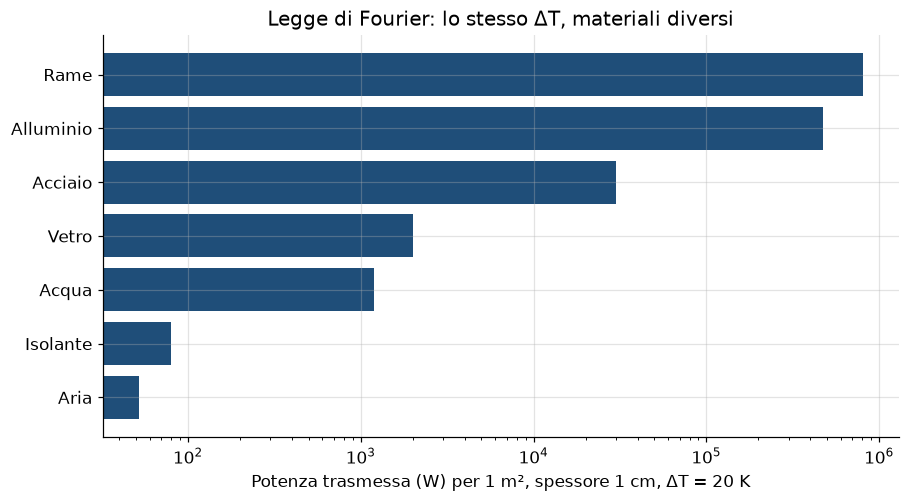

materiale      R_th (K/W)    potenza (W)
Rame            2.494e-05       8.02e+05
Alluminio       4.219e-05       4.74e+05
Acciaio         0.0006667          3e+04
Vetro                0.01           2000
Acqua             0.01667           1200
Isolante             0.25             80
Aria               0.3846             52

Il rame trasmette 15423 volte più dell'aria, a parità di geometria.


In [2]:
# Valori tipici di conducibilità, usati solo per confrontare gli ordini di grandezza.
K = {
    "Rame": 401.0,
    "Alluminio": 237.0,
    "Acciaio": 15.0,
    "Vetro": 1.0,
    "Acqua": 0.60,
    "Isolante": 0.04,
    "Aria": 0.026,
}

d = 0.01          # m, spessore
A = 1.0           # m^2
dT = 20.0         # K
names = list(K)
R = np.array([d / (K[n] * A) for n in names])
P = dT / R        # W

fig, ax = plt.subplots()
ax.barh(names[::-1], P[::-1], color="#1f4e79")
ax.set_xscale("log")
ax.set_xlabel("Potenza trasmessa (W) per 1 m², spessore 1 cm, ΔT = 20 K")
ax.set_title("Legge di Fourier: lo stesso ΔT, materiali diversi")
fig.tight_layout()
plt.show()

print(f"{'materiale':12} {'R_th (K/W)':>12} {'potenza (W)':>14}")
for n, r, p in zip(names, R, P):
    print(f"{n:12} {r:12.4g} {p:14.4g}")
print("\nIl rame trasmette", f"{P[0]/P[-1]:.0f}", "volte più dell'aria, a parità di geometria.")


## 2. Parete a due strati

In condizioni stazionarie e senza generazione interna il flusso \(q\) è lo
stesso nei due strati, e la temperatura è lineare in ciascuno:

\[
q = \frac{T_1-T_2}{d_1/k_1 + d_2/k_2},
\qquad
T_m = T_1 - q\,\frac{d_1}{k_1}.
\]

Il salto di temperatura si concentra nello strato più resistivo, non in quello
più spesso.


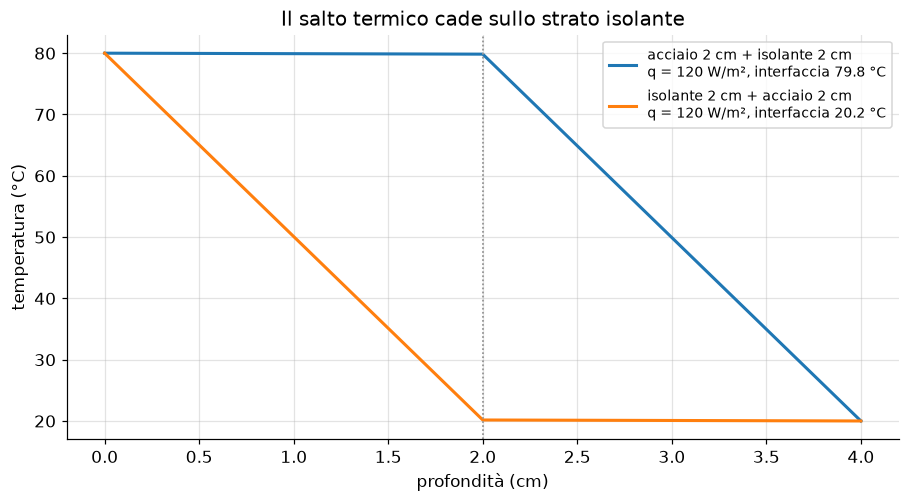

Interfaccia acciaio/isolante a 79.84 °C: l'acciaio è quasi isotermo.


In [3]:
def profilo_bistrato(d1, k1, d2, k2, T1, T2, n=80):
    q = (T1 - T2) / (d1 / k1 + d2 / k2)
    Tm = T1 - q * d1 / k1
    x1 = np.linspace(0.0, d1, n)
    x2 = np.linspace(d1, d1 + d2, n)
    T_left = T1 + (Tm - T1) * x1 / d1
    T_right = Tm + (T2 - Tm) * (x2 - d1) / d2
    return np.concatenate([x1, x2]), np.concatenate([T_left, T_right]), q, Tm

# 2 cm di acciaio + 2 cm di isolante, facce a 80 °C e 20 °C.
# Poi gli spessori scambiati, per vedere chi decide il salto.
casi = {
    "acciaio 2 cm + isolante 2 cm": (0.02, 15.0, 0.02, 0.04),
    "isolante 2 cm + acciaio 2 cm": (0.02, 0.04, 0.02, 15.0),
}

fig, ax = plt.subplots()
for nome, (d1, k1, d2, k2) in casi.items():
    x, T, q, Tm = profilo_bistrato(d1, k1, d2, k2, 80.0, 20.0)
    ax.plot(x * 100, T, lw=2, label=f"{nome}\nq = {q:.0f} W/m², interfaccia {Tm:.1f} °C")
    ax.axvline(d1 * 100, color="0.6", ls=":", lw=1)
ax.set_xlabel("profondità (cm)")
ax.set_ylabel("temperatura (°C)")
ax.set_title("Il salto termico cade sullo strato isolante")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

x, T, q, Tm = profilo_bistrato(0.02, 15.0, 0.02, 0.04, 80.0, 20.0)
assert np.isclose(T[0], 80.0) and np.isclose(T[-1], 20.0)
assert Tm > 70.0   # quasi tutto il salto è nell'isolante
print(f"Interfaccia acciaio/isolante a {Tm:.2f} °C: l'acciaio è quasi isotermo.")


## 3. Dall'equilibrio all'equazione di diffusione

Su un volumetto, la potenza che esce più la variazione di energia interna
è pari alla potenza generata dentro. Con \(\mathbf{q}=-k\nabla T\) e
proprietà costanti si ottiene l'equazione di Fourier

\[
\frac{\partial T}{\partial t} = D\,\nabla^2 T + \frac{w}{\rho c},
\qquad
D = \frac{k}{\rho c}.
\]

\(D\) è la diffusività termica (m²/s): dice quanto in fretta un profilo di
temperatura si spiana. Il tempo caratteristico su una lunghezza \(L\) è

\[
t_D \sim \frac{L^2}{D}.
\]

La scala è quadratica. Raddoppiare lo spessore quadruplica il tempo.


In [4]:
# k [W/m/K], rho [kg/m^3], c [J/kg/K]. Valori tipici da manuale.
MAT = {
    "Rame":        (401.0, 8960.0, 385.0),
    "Alluminio":   (237.0, 2700.0, 900.0),
    "Bronzo":      (50.0,  8700.0, 380.0),
    "Acciaio":     (15.0,  7800.0, 500.0),
    "Vetro":       (1.0,   2500.0, 750.0),
    "Acqua":       (0.60,  1000.0, 4180.0),
    "Aria":        (0.026, 1.16,   1007.0),
}

def proprieta(nome):
    k, rho, c = MAT[nome]
    D = k / (rho * c)
    e = np.sqrt(k * rho * c)   # effusività, J / (m² K s^0.5)
    return k, rho, c, D, e

print(f"{'materiale':12} {'D (mm²/s)':>12} {'e (kJ/m²Ks½)':>16} {'t(1 mm)':>10}")
for nome in MAT:
    _, _, _, D, e = proprieta(nome)
    t_mm = (1e-3) ** 2 / D
    print(f"{nome:12} {D*1e6:12.3f} {e/1e3:16.2f} {t_mm*1e3:8.2f} ms")

# Bronzo, L = 2,1 mm: è lo spessore dell'esempio sperimentale della lezione.
_, _, _, D_br, _ = proprieta("Bronzo")
L = 2.1e-3
print(f"\nBronzo, L = 2,1 mm: t_D = L²/D = {L**2 / D_br:.2f} s.")
print("Intorno a questo tempo l'impulso «sente» la faccia posteriore.")


materiale       D (mm²/s)     e (kJ/m²Ks½)    t(1 mm)
Rame              116.245            37.19     8.60 ms
Alluminio          97.531            24.00    10.25 ms
Bronzo             15.124            12.86    66.12 ms
Acciaio             3.846             7.65   260.00 ms
Vetro               0.533             1.37  1875.00 ms
Acqua               0.144             1.58  6966.67 ms
Aria               22.258             0.01    44.93 ms

Bronzo, L = 2,1 mm: t_D = L²/D = 0.29 s.
Intorno a questo tempo l'impulso «sente» la faccia posteriore.


## 4. Impulso istantaneo: funzione di Green

In un mezzo infinito un impulso unitario di energia rilasciato nell'origine
a \(t=0\) produce

\[
G(r,t) = \frac{1}{\rho c\,(4\pi D t)^{3/2}}
\exp\!\left(-\frac{r^2}{4Dt}\right).
\]

A distanza fissata la temperatura ha un massimo, poi ricade. Sulla sorgente
il decadimento è \(t^{-3/2}\).

Per un corpo **semi-infinito** scaldato in superficie da un lampo di fluenza
\(Q\) (J/m²) tutto il calore va verso l'interno e

\[
T(z,t) = \frac{Q}{e\sqrt{\pi t}}
\exp\!\left(-\frac{z^2}{4Dt}\right),
\qquad
e=\sqrt{k\rho c}.
\]

In superficie resta solo il fattore \(t^{-1/2}\): in scala log-log è una retta
di pendenza \(-1/2\).


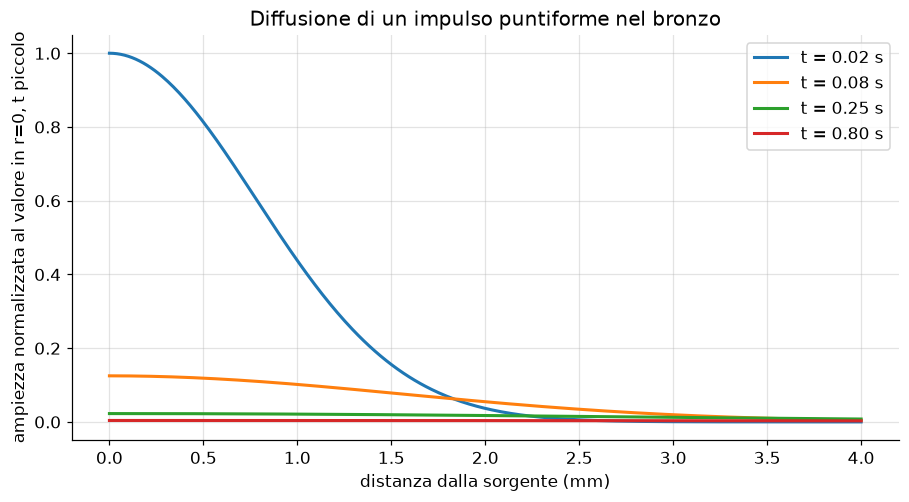

Massimo a r = 1 mm: t = 11.0 ms (atteso r²/6D = 11.0 ms).


In [5]:
k, rho, c, D, e = proprieta("Bronzo")

# Green 3D: profili a tempi crescenti, normalizzati sul massimo iniziale.
r = np.linspace(0.0, 4e-3, 400)
tempi = [0.02, 0.08, 0.25, 0.8]   # s

fig, ax = plt.subplots()
for t in tempi:
    G = np.exp(-r**2 / (4 * D * t)) / (4 * np.pi * D * t) ** 1.5
    ax.plot(r * 1e3, G / G.max() * (tempi[0] / t) ** 1.5, lw=2, label=f"t = {t:.2f} s")
ax.set_xlabel("distanza dalla sorgente (mm)")
ax.set_ylabel("ampiezza normalizzata al valore in r=0, t piccolo")
ax.set_title("Diffusione di un impulso puntiforme nel bronzo")
ax.legend()
fig.tight_layout()
plt.show()

# Il massimo a distanza r arriva a t = r² / (6D).
r0 = 1e-3
t_max_atteso = r0**2 / (6 * D)
t_grid = np.geomspace(1e-3, 2.0, 2000)
G_t = np.exp(-r0**2 / (4 * D * t_grid)) / t_grid ** 1.5
t_max = t_grid[np.argmax(G_t)]
print(f"Massimo a r = 1 mm: t = {t_max*1e3:.1f} ms (atteso r²/6D = {t_max_atteso*1e3:.1f} ms).")
assert np.isclose(t_max, t_max_atteso, rtol=0.02)


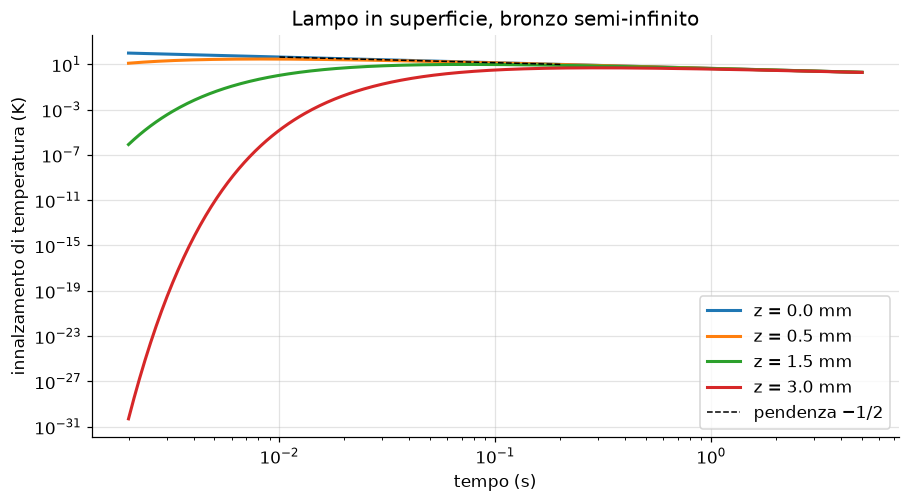

Pendenza log-log in superficie: -0.500 (atteso −0.5).


In [6]:
# Superficie di un semi-infinito: pendenza -1/2. In profondità il lampo arriva in ritardo.
Q = 1e5  # J/m²
z = np.array([0.0, 0.5e-3, 1.5e-3, 3e-3])
t = np.geomspace(2e-3, 5.0, 400)

fig, ax = plt.subplots()
for zi in z:
    T = Q / (e * np.sqrt(np.pi * t)) * np.exp(-zi**2 / (4 * D * t))
    ax.loglog(t, T, lw=2, label=f"z = {zi*1e3:.1f} mm")

t_ref = np.array([0.01, 0.2])
T_ref = Q / (e * np.sqrt(np.pi * t_ref))
# retta guida di pendenza -1/2, ancorata al primo punto della superficie
scala = T_ref[0] / t_ref[0] ** (-0.5)
ax.loglog(t_ref, scala * t_ref ** (-0.5), "k--", lw=1, label="pendenza −1/2")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("innalzamento di temperatura (K)")
ax.set_title("Lampo in superficie, bronzo semi-infinito")
ax.legend()
fig.tight_layout()
plt.show()

# Controllo della pendenza in superficie fra 0,05 s e 0,5 s.
t_a, t_b = 0.05, 0.5
Ta = Q / (e * np.sqrt(np.pi * t_a))
Tb = Q / (e * np.sqrt(np.pi * t_b))
pendenza = np.log(Tb / Ta) / np.log(t_b / t_a)
print(f"Pendenza log-log in superficie: {pendenza:.3f} (atteso −0.5).")
assert np.isclose(pendenza, -0.5, atol=1e-6)


## 5. Una discontinuità a profondità \(L\)

Se a profondità \(L\) il materiale cambia, l'onda di calore si riflette.
Il coefficiente di riflessione delle temperature, scritto con le effusività
\(e=\sqrt{k\rho c}\), è

\[
R = \frac{e_1-e_2}{e_1+e_2}.
\]

\(R\to +1\) se dietro c'è un isolante, \(R\to -1\) se dietro c'è un pozzo
termico (effusività molto più alta). La temperatura in superficie diventa
la serie di echi della lezione

\[
T(0,t)=\frac{Q}{e\sqrt{\pi t}}
\left[1+2\sum_{n=1}^{\infty} R^{\,n}
\exp\!\left(-\frac{n^2 L^2}{Dt}\right)\right].
\]

A tempi molto lunghi, con la faccia posteriore isolata (\(R=1\)), il calore
si è ridistribuito e

\[
T_\infty = \frac{Q}{\rho c L}.
\]

La serie, grazie alla formula di sommazione di Poisson, ci arriva da sola.


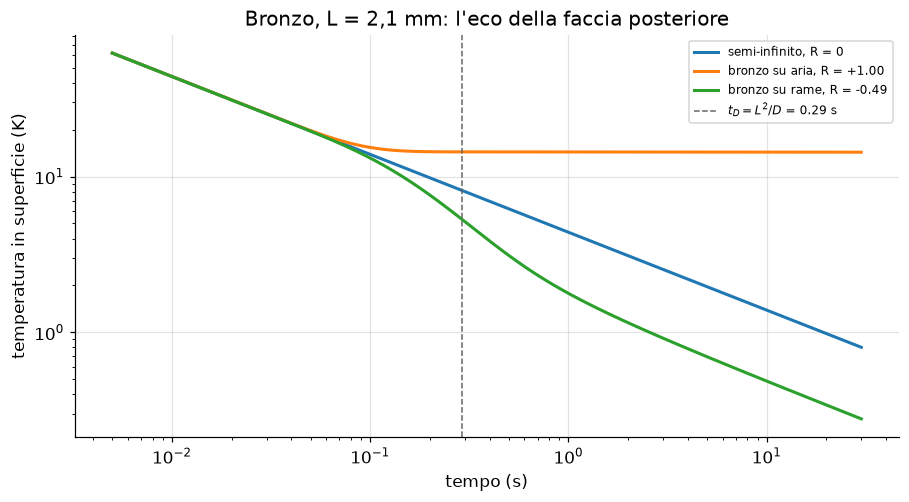

Equilibrio atteso Q/(ρ c L) = 14.404 K
Serie a t = 200 s, R = 1     = 14.404 K


In [7]:
def T_superficie(t, Q, e, D, L, R, n_max=80):
    """Temperatura in superficie dopo un lampo, con un'interfaccia a profondità L."""
    t = np.asarray(t, dtype=float)
    serie = np.ones_like(t)
    for n in range(1, n_max + 1):
        serie = serie + 2.0 * R**n * np.exp(-(n * L) ** 2 / (D * t))
    return Q / (e * np.sqrt(np.pi * t)) * serie

_, rho, c, D, e = proprieta("Bronzo")
L = 2.1e-3
Q = 1e5
t = np.geomspace(5e-3, 30.0, 500)

# Aria: effusività minuscola, R ≈ +1. Rame: effusività più alta del bronzo, R < 0.
_, _, _, _, e_aria = proprieta("Aria")
_, _, _, _, e_cu = proprieta("Rame")
riflessioni = {
    "semi-infinito, R = 0": 0.0,
    f"bronzo su aria, R = {(e-e_aria)/(e+e_aria):+.2f}": (e - e_aria) / (e + e_aria),
    f"bronzo su rame, R = {(e-e_cu)/(e+e_cu):+.2f}": (e - e_cu) / (e + e_cu),
}

fig, ax = plt.subplots()
for nome, R in riflessioni.items():
    ax.loglog(t, T_superficie(t, Q, e, D, L, R), lw=2, label=nome)
ax.axvline(L**2 / D, color="0.4", ls="--", lw=1, label=fr"$t_D=L^2/D$ = {L**2/D:.2f} s")
ax.set_xlabel("tempo (s)")
ax.set_ylabel("temperatura in superficie (K)")
ax.set_title("Bronzo, L = 2,1 mm: l'eco della faccia posteriore")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Faccia posteriore isolata: a t >> t_D la temperatura tende a Q/(ρ c L).
T_inf = Q / (rho * c * L)
T_tardi = T_superficie(np.array([200.0]), Q, e, D, L, R=1.0, n_max=400)[0]
print(f"Equilibrio atteso Q/(ρ c L) = {T_inf:.3f} K")
print(f"Serie a t = 200 s, R = 1     = {T_tardi:.3f} K")
assert np.isclose(T_tardi, T_inf, rtol=0.02)


## In sintesi

- Il flusso è \(\mathbf{q}=-k\nabla T\); in una parete piana stazionaria gli strati sono resistenze in serie.
- La diffusività \(D=k/(\rho c)\) fissa il tempo \(L^2/D\). Nel bronzo oftenuto a lezione (\(L=2{,}1\,\mathrm{mm}\)) questo tempo è di qualche decimo di secondo.
- Dopo un lampo superficiale, \(\log T\) contro \(\log t\) ha pendenza \(-1/2\) finché il calore non incontra un'interfaccia.
- Il segno di \(R=(e_1-e_2)/(e_1+e_2)\) dice se la faccia posteriore restituisce calore o lo assorbe. È lo stesso coefficiente che, in regime periodico, diventa lo specchio termico della lezione 3.
